In [1]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period')
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

In [2]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral.sort_index()

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [3]:

import warnings
warnings.filterwarnings("ignore")
import itertools,copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from torch.utils.data import DataLoader,TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

class VanillaLSTM(nn.Module):
    def __init__(self,neurons,dropout,horizon):
        super().__init__()
        self.lstms=nn.ModuleList()
        input_size=1
        for n in neurons:
            self.lstms.append(nn.LSTM(input_size=input_size,hidden_size=n,num_layers=1,batch_first=True))
            input_size=n
        self.dropout=nn.Dropout(dropout)
        self.fc=nn.Linear(neurons[-1],horizon)

    def forward(self,x):
        for i,lstm in enumerate(self.lstms):
            x,_=lstm(x)
            if i<len(self.lstms)-1:
                x=self.dropout(x)
        if len(self.lstms)==1:
            x=self.dropout(x[:,-1,:])
        else:
            x=x[:,-1,:]
        return self.fc(x)
def create_sequences(data,window,start,end,horizon):
    X=np.array([data[i-window:i] for i in range(start,end-horizon+1)],dtype=np.float32)
    y=np.array([data[i:i+horizon] for i in range(start,end-horizon+1)],dtype=np.float32)
    return X.reshape(-1,window,1),y.reshape(-1,horizon)



neuron_options=[32,64,128]
architectures=[(n,) for n in neuron_options]+[(n1,n2) for n1 in neuron_options for n2 in neuron_options if n1>=n2]
# Define the hyperparameter search space for lstm models
# learning rates to try
learning_rates=[0.01,0.001]
# window sizes to try
window_sizes=[4,6,8]
# epochs to try
epochs_options=[100]
# batch sizes to try
batch_sizes=[16,32]
# dropout rates to try
dropout_options=[0.0,0.1,0.3]

params=list(itertools.product(architectures,learning_rates,window_sizes,epochs_options,batch_sizes,dropout_options))
patience,min_delta=15,1e-5
lstm_models,results={},[]
H=len(test)

for col in train.columns:
    y_train=train[col].dropna().to_numpy(dtype=np.float32)
    y_val=val[col].dropna().to_numpy(dtype=np.float32)
    candidatos=[]
    if len(y_train)<=8 or len(y_val)==0:
        lstm_models[col]=[]
        print(f"{col} (sin datos suficientes)")
        continue
    scaler=MinMaxScaler()
    train_scaled=scaler.fit_transform(y_train.reshape(-1,1)).flatten()
    val_scaled=scaler.transform(y_val.reshape(-1,1)).flatten()
    for neurons,lr,window,epochs,batch_size,dropout in params:
        if len(y_train)<=window:
            continue
        torch.manual_seed(42)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42)
        layers=len(neurons)
        X_train,Y_train=create_sequences(train_scaled,window,window,len(y_train),H)
        loader=DataLoader(TensorDataset(torch.tensor(X_train),torch.tensor(Y_train)),batch_size=batch_size,shuffle=False)
        X_val_t=torch.tensor(train_scaled[-window:].reshape(1,window,1),dtype=torch.float32,device=device)
        hval=min(H,len(y_val))
        Y_val_t=torch.tensor(val_scaled[:hval].reshape(1,-1),dtype=torch.float32,device=device)
        model=VanillaLSTM(neurons,dropout,H).to(device)
        optimizer=torch.optim.Adam(model.parameters(),lr=lr)
        criterion=nn.MSELoss()
        best_val_loss=float("inf")
        best_state=None
        best_epoch=counter=epochs_trained=0
        for epoch in range(epochs):
            model.train()
            for xb,yb in loader:
                xb,yb=xb.to(device),yb.to(device)
                optimizer.zero_grad()
                loss=criterion(model(xb),yb)
                loss.backward()
                optimizer.step()
            model.eval()
            with torch.no_grad():
                val_loss=criterion(model(X_val_t)[:,:hval],Y_val_t).item()
            epochs_trained=epoch+1
            if not np.isfinite(val_loss):
                break
            if val_loss<best_val_loss-min_delta:
                best_val_loss=val_loss
                best_state=copy.deepcopy(model.state_dict())
                best_epoch=epoch+1
                counter=0
            else:
                counter+=1
            if counter>=patience:
                break
        if best_state is None:
            del model
            continue
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            pred_scaled=model(X_val_t).cpu().numpy()[:,:hval]
            fitted_scaled=model(torch.tensor(X_train,device=device)).cpu().numpy()[:,0:1]
        pred=scaler.inverse_transform(pred_scaled.reshape(-1,1)).flatten()
        fitted=scaler.inverse_transform(fitted_scaled).flatten()
        real=y_val[:hval]
        values=y_train
        if not np.all(np.isfinite(pred)) or not np.all(np.isfinite(fitted)):
            del model
            continue
        mae=mean_absolute_error(real,pred)
        mse=mean_squared_error(real,pred)
        rmse=np.sqrt(mse)
        mask=real!=0
        mape=np.mean(np.abs((real[mask]-pred[mask])/real[mask]))*100 if mask.any() else np.nan
        scale=np.mean(np.abs(values[4:]-values[:-4])) if len(values)>4 else np.nan
        mase=mae/scale if np.isfinite(scale) and scale>0 else np.nan
        rmsee=np.sqrt(np.mean((values[window:window+len(fitted)]-fitted)**2))
        r2=r2_score(real,pred) if len(real)>1 else np.nan
        candidatos.append({
            "Serie":col,"Layers":layers,"Neurons":"-".join(map(str,neurons)),
            "Optimizer":"Adam","Learning_Rate":lr,"Window":window,
            "Epochs":epochs,"Best_Epoch":best_epoch,"Epochs_Trained":epochs_trained,
            "Batch_Size":batch_size,"Dropout":dropout,"MAE":mae,"MSE":mse,
            "RMSE":rmse,"MAPE":mape,"MASE":mase,"RMSEE":rmsee,"R2":r2
        })
        del model
    candidatos=sorted(candidatos,key=lambda x:x["RMSE"])
    lstm_models[col]=candidatos[:10]
    for rank,result in enumerate(candidatos[:10],start=1):
        results.append({"Serie":col,"Rank":rank,**{k:v for k,v in result.items() if k!="Serie"}})
    print(f"{col} (ok)")

top10_lstm=pd.DataFrame(results).round(4)
BASE=Path(BASE) if "BASE" in globals() else Path(".")
(BASE/"results"/"LSTM").mkdir(parents=True,exist_ok=True)
top10_lstm.to_csv(BASE/"results"/"LSTM"/"top10_lstm.csv",index=False)
display(top10_lstm)


15-34 M (ok)
15-34 F (ok)
35-49 M (ok)
35-49 F (ok)
50-74 M (ok)
50-74 F (ok)
Global_Rate (ok)


,Serie,Rank,Layers,Neurons,Optimizer,Learning_Rate,Window,Epochs,Best_Epoch,Epochs_Trained,Batch_Size,Dropout,MAE,MSE,RMSE,MAPE,MASE,RMSEE,R2
0,15-34 M,1,2,128-128,Adam,0.01,4,100,3,18,32,0.1,1.5467,4.0395,2.0099,10.3263,0.9544,4.5191,0.2243
1,15-34 M,2,2,128-128,Adam,0.01,4,100,3,18,32,0.0,1.5626,4.0773,2.0192,10.4683,0.9642,4.4976,0.2171
2,15-34 M,3,2,128-128,Adam,0.01,4,100,3,18,32,0.3,1.5980,4.1736,2.0429,10.6951,0.9861,4.5394,0.1986
3,15-34 M,4,1,64,Adam,0.01,6,100,5,20,32,0.1,1.7314,4.7074,2.1697,11.8280,1.0684,4.5029,0.0961
4,15-34 M,5,2,64-64,Adam,0.01,4,100,4,19,32,0.0,1.8835,4.8784,2.2087,12.6896,1.1622,4.9965,0.0633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,Global_Rate,6,1,64,Adam,0.01,4,100,5,20,32,0.1,0.7607,0.8511,0.9225,8.7692,0.9130,2.1673,-0.0383
66,Global_Rate,7,1,64,Adam,0.01,8,100,5,20,16,0.0,0.8270,0.8549,0.9246,9.2850,0.9926,2.4321,-0.0430
67,Global_Rate,8,2,64-64,Adam,0.01,4,100,4,19,32,0.0,0.8388,0.8632,0.9291,9.6171,1.0067,2.3100,-0.0532
68,Global_Rate,9,1,64,Adam,0.01,4,100,5,20,32,0.0,0.7612,0.8634,0.9292,8.8287,0.9135,2.1499,-0.0533


In [4]:
# Parámetros ganadores del Grid Search multi-step (Rank 1 de cada serie)
# Serie          Layers   Neurons    Learning_Rate   Window   Epochs   Batch_Size   Dropout
for col,candidates in lstm_models.items():
    if candidates:
        best=candidates[0]
        print(f"# {col:<14} {best['Layers']:<8} {best['Neurons']:<10} {best['Learning_Rate']:<15} {best['Window']:<8} {best['Best_Epoch']:<8} {best['Batch_Size']:<12} {best['Dropout']}")


# 15-34 M        2        128-128    0.01            4        3        32           0.1
# 15-34 F        2        128-128    0.01            4        3        32           0.0
# 35-49 M        2        64-32      0.01            4        5        32           0.1
# 35-49 F        2        128-64     0.01            4        13       32           0.0
# 50-74 M        2        64-64      0.01            4        4        32           0.1
# 50-74 F        1        128        0.01            4        99       16           0.0
# Global_Rate    2        128-128    0.01            4        3        32           0.0


In [5]:

lstm_best_params = {
    col: {
        "neurons":tuple(map(int,top["Neurons"].split("-"))),
        "lr":top["Learning_Rate"],"window":top["Window"],
        "epochs":top["Best_Epoch"],"batch_size":top["Batch_Size"],
        "dropout":top["Dropout"]
    }
    for col,candidates in lstm_models.items() if candidates
    for top in candidates[:1]
}

lstm_results={}
lstm_predictions={}

for col,params in lstm_best_params.items():
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
    y_train_val=pd.concat([train[col],val[col]]).dropna().to_numpy(dtype=np.float32)
    y_test=test[col].dropna().to_numpy(dtype=np.float32)
    scaler=MinMaxScaler()
    train_val_scaled=scaler.fit_transform(y_train_val.reshape(-1,1)).flatten()
    window=params["window"]
    H=len(y_test)
    X_train,Y_train=create_sequences(train_val_scaled,window,window,len(y_train_val),H)
    loader=DataLoader(TensorDataset(torch.tensor(X_train),torch.tensor(Y_train)),batch_size=params["batch_size"],shuffle=False)
    model=VanillaLSTM(params["neurons"],params["dropout"],H).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=params["lr"])
    criterion=nn.MSELoss()
    for epoch in range(params["epochs"]):
        model.train()
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device)
            optimizer.zero_grad()
            loss=criterion(model(xb),yb)
            loss.backward()
            optimizer.step()
    model.eval()
    x=torch.tensor(train_val_scaled[-window:].reshape(1,window,1),dtype=torch.float32,device=device)
    with torch.no_grad():
        pred_scaled=model(x).cpu().numpy()
    pred=scaler.inverse_transform(pred_scaled.reshape(-1,1)).flatten()
    lstm_predictions[col]=pred
    real=y_test
    mse=mean_squared_error(real,pred)
    rmse=np.sqrt(mse)
    mae=mean_absolute_error(real,pred)
    mask=real!=0
    mape=np.mean(np.abs((real[mask]-pred[mask])/real[mask]))*100 if mask.any() else np.nan
    r2=r2_score(real,pred) if len(real)>1 else np.nan
    lstm_results[col]={
        "MSE":mse,"RMSE":rmse,"MAE":mae,"MAPE":mape,"R2":r2,
        "Layers":len(params["neurons"]),"Neurons":"-".join(map(str,params["neurons"])),
        "Learning_Rate":params["lr"],"Window":window,"Epochs":params["epochs"],
        "Batch_Size":params["batch_size"],"Dropout":params["dropout"]
    }
    print(f"{col} (ok)")

lstm_results_df=pd.DataFrame(lstm_results).T.round(4)
(BASE/"results"/"LSTM").mkdir(parents=True,exist_ok=True)
lstm_predictions_df=pd.DataFrame(lstm_predictions).T
lstm_predictions_df.to_csv(BASE/"results"/"LSTM"/"lstm_predictions.csv",index=True)
lstm_results_df.to_csv(BASE/"results"/"LSTM"/"lstm_results.csv",index=True)
display(lstm_results_df)

15-34 M (ok)
15-34 F (ok)
35-49 M (ok)
35-49 F (ok)
50-74 M (ok)
50-74 F (ok)
Global_Rate (ok)


,MSE,RMSE,MAE,MAPE,R2,Layers,Neurons,Learning_Rate,Window,Epochs,Batch_Size,Dropout
15-34 M,23.268965,4.823792,4.612159,41.871204,-18.040991,2,128-128,0.01,4,3,32,0.1
15-34 F,36.033428,6.002785,5.831518,46.642609,-13.834128,2,128-128,0.01,4,3,32,0.0
35-49 M,1.571288,1.25351,1.034736,22.502882,-3.387187,2,64-32,0.01,4,5,32,0.1
35-49 F,5.069378,2.251528,1.93976,30.501991,-3.021751,2,128-64,0.01,4,13,32,0.0
50-74 M,1.164801,1.079259,0.877338,26.451059,-2.212677,2,64-64,0.01,4,4,32,0.1
50-74 F,2.630768,1.621964,1.365666,36.579391,-1.962807,1,128,0.01,4,99,16,0.0
Global_Rate,5.533773,2.352397,2.209827,35.295467,-5.61799,2,128-128,0.01,4,3,32,0.0


In [6]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

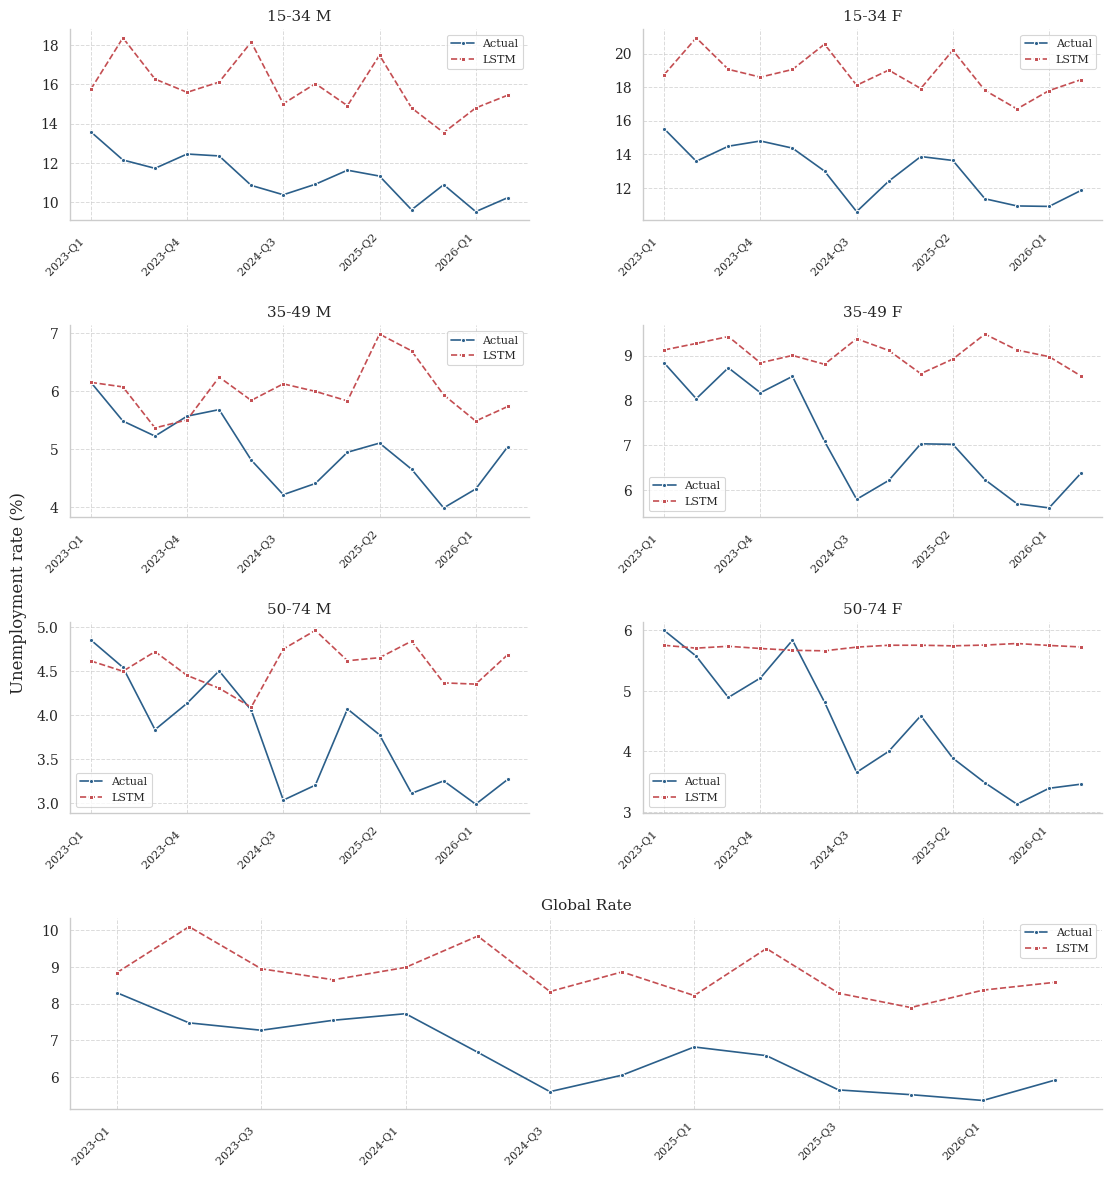

In [7]:
# Vamos a plotear los resultados 

series = ["15-34 M", "15-34 F", "35-49 M", "35-49 F", "50-74 M", "50-74 F", "Global_Rate"]
x = test.index

fig = plt.figure(figsize=(12, 12))
gs = fig.add_gridspec(4, 2, hspace=0.55, wspace=0.25)
axes = [fig.add_subplot(gs[i // 2, i % 2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3, :]))

for i, (ax, col) in enumerate(zip(axes, series)):
    sns.lineplot(x=x, y=test[col].to_numpy(), ax=ax,
                 color="#2B5F8A", marker="o", markersize=3,
                 linewidth=1.2, label="Actual")

    sns.lineplot(x=x, y=lstm_predictions[col], ax=ax,
                 color="#C44E52", marker="s", markersize=3,
                 linewidth=1.2, linestyle="--", label="LSTM")

    ax.set_title(col.replace("_", " "), fontsize=11)
    ax.set(xlabel="", ylabel="")
    ticks = x[::2] if i == 6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks, rotation=45, ha="right", fontsize=8)
    ax.grid(True, axis="both", linestyle="--", linewidth=0.7, alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)", fontsize=12, x=0.07)
fig.subplots_adjust(left=0.12, right=0.98, top=0.97, bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG / "lstm_forecast_test.pdf", bbox_inches="tight")
plt.show()
# LSTM multi-step directa sobre el conjunto de test.

In [8]:
# Calcular los IC en el test set
rng = np.random.default_rng(42)
B = 2000
block_size = 4
ci_results = []

for col in lstm_best_params:
    real = test[col].to_numpy()
    pred = np.asarray(lstm_predictions[col])
    n = len(real)

    if n < block_size:
        raise ValueError(f"{col}: test too short for blocks of {block_size}")

    metrics = {"MSE": [], "RMSE": [], "MAE": [], "MAPE": []}

    for _ in range(B):
        starts = rng.integers(0, n-block_size+1, size=int(np.ceil(n/block_size)))
        idx = np.concatenate([np.arange(s,s+block_size) for s in starts])[:n]

        y_b = real[idx]
        p_b = pred[idx]
        errors = y_b-p_b

        mse_b = np.mean(errors**2)
        metrics["MSE"].append(mse_b)
        metrics["RMSE"].append(np.sqrt(mse_b))
        metrics["MAE"].append(np.mean(np.abs(errors)))

        mask = y_b != 0
        metrics["MAPE"].append(
            np.mean(np.abs(errors[mask]/y_b[mask]))*100
            if mask.any() else np.nan
        )

    row = {"Serie": col}
    point_metrics = {
        "MSE": np.mean((real-pred)**2),
        "RMSE": np.sqrt(np.mean((real-pred)**2)),
        "MAE": np.mean(np.abs(real-pred)),
        "MAPE": np.mean(np.abs((real[real!=0]-pred[real!=0])/real[real!=0]))*100 if np.any(real!=0) else np.nan
    }

    for metric, values in metrics.items():
        lower = np.nanpercentile(values, 2.5)
        upper = np.nanpercentile(values, 97.5)
        row[metric] = round(point_metrics[metric], 4)
        row[f"{metric} IC 95%"] = f"[{lower:.4f}, {upper:.4f}]"

    ci_results.append(row)

lstm_ci_df = pd.DataFrame(ci_results)
(BASE/"results"/"LSTM").mkdir(parents=True, exist_ok=True)
lstm_ci_df.to_csv(BASE/"results"/"LSTM"/"lstm_IC_test.csv", index=False)
display(lstm_ci_df)

,Serie,MSE,MSE IC 95%,RMSE,RMSE IC 95%,MAE,MAE IC 95%,MAPE,MAPE IC 95%
0,15-34 M,23.2690,"[20.2936, 27.3987]",4.8238,"[4.5048, 5.2344]",4.6122,"[4.2928, 5.0536]",41.8712,"[36.8171, 46.8638]"
1,15-34 F,36.0334,"[28.9212, 42.5671]",6.0028,"[5.3778, 6.5243]",5.8315,"[5.1792, 6.4303]",46.6426,"[38.2964, 54.1891]"
2,35-49 M,1.5713,"[0.6259, 2.8416]",1.2535,"[0.7911, 1.6857]",1.0347,"[0.5312, 1.6245]",22.5029,"[10.9629, 35.5742]"
3,35-49 F,5.0694,"[1.9766, 8.1453]",2.2515,"[1.4059, 2.8540]",1.9398,"[1.1093, 2.7284]",30.5020,"[15.7083, 44.7118]"
4,50-74 M,1.1648,"[0.5069, 1.8234]",1.0793,"[0.7120, 1.3503]",0.8773,"[0.4940, 1.2500]",26.4511,"[14.0024, 38.8359]"
5,50-74 F,2.6308,"[0.6562, 4.3456]",1.6220,"[0.8101, 2.0846]",1.3657,"[0.6284, 2.0103]",36.5794,"[14.0494, 56.5002]"
6,Global_Rate,5.5338,"[3.8560, 7.0543]",2.3524,"[1.9637, 2.6560]",2.2098,"[1.7945, 2.6054]",35.2955,"[25.9031, 43.4867]"
